# Assignment 03

**姓名：** 伍奕　　**学号：** 12632770

- 1. 全球甲烷（C3S XCH4 v4.3，2003-01 ~ 2020-06，5°×5°）
- 2. Niño 3.4 指数（NOAA ERSST v3b，1960-01 ~ 2016-12）
- 3. 探索一个 netCDF 数据集（ERA5-Land 月平均 2 米气温，中国区域，2000–2023）

> 注：本机用户目录含中文，`netCDF4` 在 Windows 下打不开中文**绝对**路径，
> 所以统一用 `load_nc()`：把文件读进内存再加载。数据放在 notebook 同级的 `S08data/` 下。

In [ ]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import netCDF4
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


def load_nc(path):
    # Windows 下 netCDF4 处理不了含中文的绝对路径（本机用户目录是 C:\Users\雪）。
    # 相对路径由 C 库按当前工作目录解析，可以正常打开；
    # 万一失败，再把文件读进内存加载（注意 netCDF4 同时只允许一个内存数据集）。
    try:
        nc = netCDF4.Dataset(path)
    except (FileNotFoundError, OSError):
        with open(os.path.abspath(path), "rb") as f:
            nc = netCDF4.Dataset("inmemory.nc", mode="r", memory=f.read())
    return xr.open_dataset(xr.backends.NetCDF4DataStore(nc))


DATA_DIR = "S08data"
print(sorted(os.listdir(DATA_DIR)))

['200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc', 'NOAA_NCDC_ERSST_v3b_SST.nc', 'era5_land_t2m_china_2000_2023.nc', 'sst.mnmean.nc']


## 1. Global methane levels from 2002

文件：`200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc`
变量 `xch4`：柱平均干空气甲烷摩尔分数，单位是 1（即 ppb/1e9），缺测填 `1e20`，
网格 5°×5°（lat 36、lon 72），时间 2003-01 至 2020-06 共 210 个月。

In [ ]:
ds_ch4 = load_nc(os.path.join(
    DATA_DIR, "200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc"))

xch4 = ds_ch4["xch4"]
xch4 = xch4.where(xch4 < 1e19)          # 1e20 是缺测
xch4 = xch4 * 1e9                       # 摩尔分数 -> ppb
xch4 = xch4.where(xch4 > 0)             # 去掉无效的 0
xch4.attrs.update(long_name="XCH4", units="ppb")

land_frac = ds_ch4["land_fraction"]     # 用来在图上勾出大陆轮廓

print(xch4.dims, xch4.shape)
print("time:", str(xch4.time.values[0])[:10], "->", str(xch4.time.values[-1])[:10])
print("lat :", float(xch4.lat.min()), "->", float(xch4.lat.max()))
print("lon :", float(xch4.lon.min()), "->", float(xch4.lon.max()))
print("global mean XCH4 = %.1f ppb" % float(xch4.mean()))

('time', 'lat', 'lon') (210, 36, 72)
time: 2003-01-16 -> 2020-06-16
lat : -87.5 -> 87.5
lon : -177.5 -> 177.5
global mean XCH4 = 1782.8 ppb


climatology range: 1576.9 - 1904.1 ppb


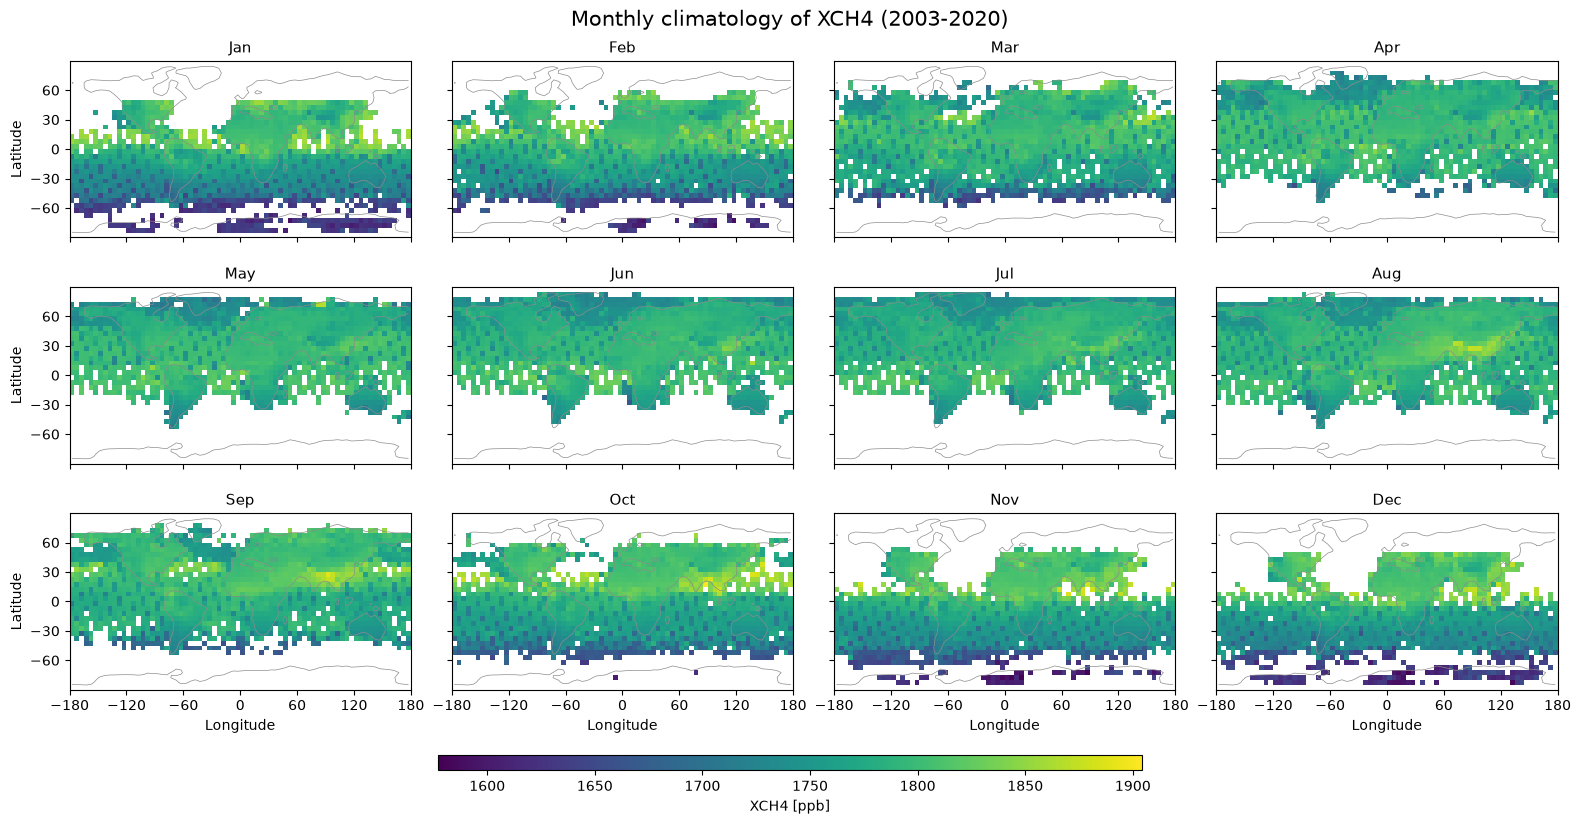

In [ ]:
# 1.1 每个月的多年气候态（12 张图）

clim = xch4.groupby("time.month").mean("time")      # (month, lat, lon)
vmin, vmax = float(clim.min()), float(clim.max())
print("climatology range: %.1f - %.1f ppb" % (vmin, vmax))

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
lon, lat = clim.lon.values, clim.lat.values

fig, axes = plt.subplots(3, 4, figsize=(16, 8.5), dpi=110,
                         sharex=True, sharey=True)
fig.subplots_adjust(left=0.05, right=0.98, top=0.90, bottom=0.16,
                    wspace=0.12, hspace=0.28)
for i, ax in enumerate(axes.ravel()):
    m = clim.isel(month=i)
    pc = ax.pcolormesh(lon, lat, m, cmap="viridis", vmin=vmin, vmax=vmax,
                       shading="auto")
    ax.contour(lon, lat, land_frac, levels=[0.5], colors="0.55", linewidths=0.5)
    ax.set_title(months[i], fontsize=11)
    ax.set_xticks([-180, -120, -60, 0, 60, 120, 180])
    ax.set_yticks([-60, -30, 0, 30, 60])

for ax in axes[-1, :]:
    ax.set_xlabel("Longitude")
for ax in axes[:, 0]:
    ax.set_ylabel("Latitude")

cax = fig.add_axes([0.28, 0.065, 0.44, 0.018])
fig.colorbar(pc, cax=cax, orientation="horizontal", label="XCH4 [ppb]")
fig.suptitle("Monthly climatology of XCH4 (2003-2020)", fontsize=15, y=0.96)

plt.show()

global mean XCH4: 1713.5 -> 1850.7 ppb
trend = 6.46 ppb/yr (64.6 ppb/decade)


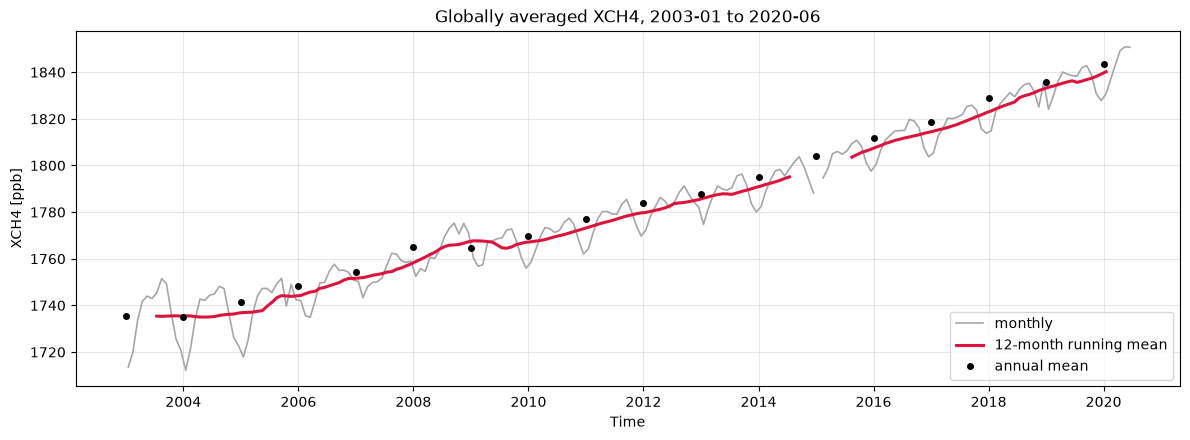

In [ ]:
# 1.2 全球平均甲烷时间序列（纬度按 cos(lat) 加权）

w = np.cos(np.deg2rad(xch4.lat))
gm = xch4.weighted(w).mean(dim=["lat", "lon"])
gm12 = gm.rolling(time=12, center=True).mean()

# 线性趋势（用年平均）。注意 groupby("time.year") 之后坐标叫 "year"，
# 要转回 datetime 才能和月度曲线共用时间轴
annual = gm.groupby("time.year").mean("time")
annual_x = pd.to_datetime(annual.year.values.astype(int).astype(str))
slope, intercept = np.polyfit(annual.year, annual, 1)
print("global mean XCH4: %.1f -> %.1f ppb" % (float(gm.isel(time=0)), float(gm.isel(time=-1))))
print("trend = %.2f ppb/yr (%.1f ppb/decade)" % (slope, slope * 10))

fig, ax = plt.subplots(figsize=(12, 4.5), dpi=110)
ax.plot(gm.time, gm, color="0.65", lw=1.2, label="monthly")
ax.plot(gm12.time, gm12, color="crimson", lw=2.2, label="12-month running mean")
ax.plot(annual_x, annual, "o", ms=4, color="k", label="annual mean")
ax.set_ylabel("XCH4 [ppb]")
ax.set_xlabel("Time")
ax.set_title("Globally averaged XCH4, 2003-01 to 2020-06")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()

plt.show()

**1.2 描述：** 全球平均 XCH4 从 2003 年 1 月的 **1713.5 ppb** 上升到 2020 年 6 月的 **1850.7 ppb**，
17.5 年间累计增加约 **137 ppb**；对年平均序列做线性拟合得到 **6.5 ppb/yr**（约 65 ppb/decade）。
曲线明显分三段：2003–2007 快速上升 → **2007–2013 基本停滞**（年均值停在 1755–1770 ppb）→
2014 年以后重新加速，2020 年达到 1830 ppb 以上。这与 [NASA SVS 的全球甲烷曲线](https://svs.gsfc.nasa.gov/5007) 的形态一致：
2007–2013 的"平台期"对应源汇大致平衡，2014 年以来的回升主要来自热带湿地排放增加和化石燃料开采；
曲线上 ±10–20 ppb 的年际起伏则与 ENSO、生物质燃烧的年际变化有关。

point lat/lon: -12.5 -147.5
climatology amplitude: 45.6 ppb (max-min)
climatology peak month: 7, trough month: 10
valid months: 77 / 210
deseasonalized change 2003 -> 2020: 49.0 ppb


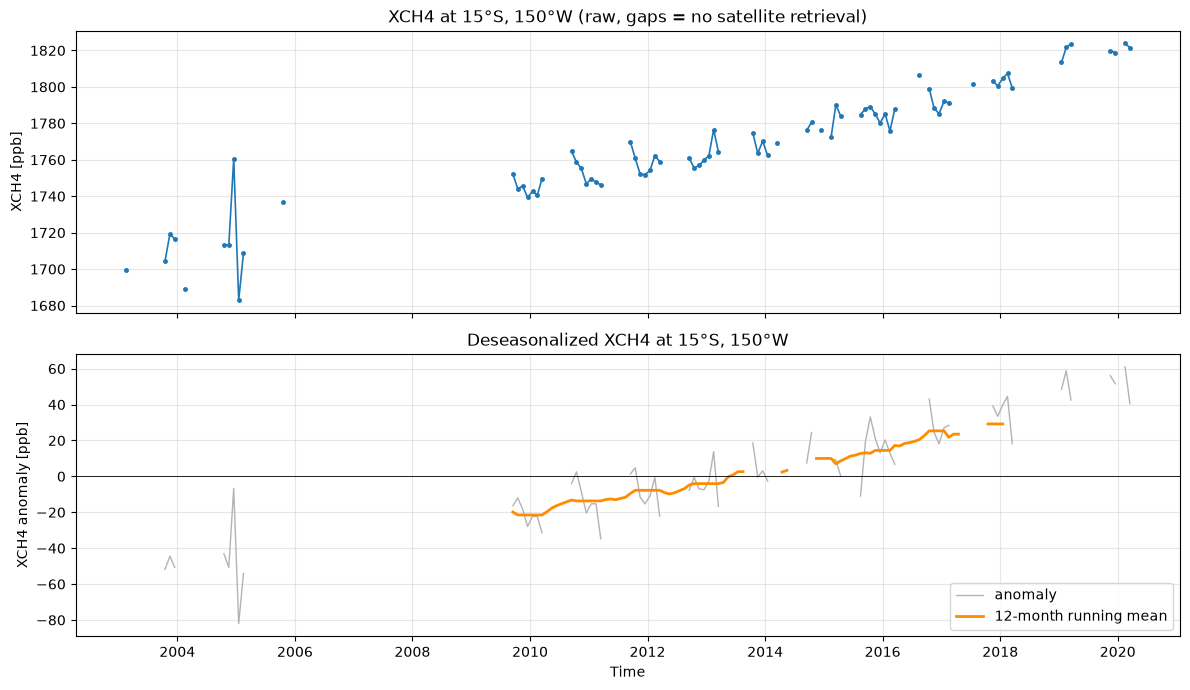

In [ ]:
# 1.3 单点 [15S, 150W] 的去季节时间序列

pt = xch4.sel(lat=-15, lon=-150, method="nearest")
pt_clim = pt.groupby("time.month").mean("time")     # (month,)
# 注意要用 groupby - clim，直接 pt - pt_clim 会广播成 (time, month)
pt_anom = pt.groupby("time.month") - pt_clim        # (time,)
pt_anom_smooth = pt_anom.rolling(time=12, center=True, min_periods=6).mean()

print("point lat/lon:", float(pt.lat), float(pt.lon))
print("climatology amplitude: %.1f ppb (max-min)" % (float(pt_clim.max() - pt_clim.min())))
print("climatology peak month: %d, trough month: %d"
      % (int(pt_clim.idxmax()), int(pt_clim.idxmin())))
print("valid months: %d / %d" % (int(pt.notnull().sum()), pt.size))
_sm = pt_anom_smooth.dropna("time")
if _sm.size:
    print("deseasonalized change 2003 -> 2020: %.1f ppb"
          % (float(_sm.isel(time=-1)) - float(_sm.isel(time=0))))

fig, axes = plt.subplots(2, 1, figsize=(12, 7), dpi=110, sharex=True)

axes[0].plot(pt.time, pt.values, ".-", color="tab:blue", lw=1.2, ms=5)
axes[0].set_ylabel("XCH4 [ppb]")
axes[0].set_title("XCH4 at 15°S, 150°W (raw, gaps = no satellite retrieval)")
axes[0].grid(alpha=0.3)

axes[1].plot(pt_anom.time, pt_anom.values, color="0.7", lw=1, label="anomaly")
axes[1].plot(pt_anom_smooth.time, pt_anom_smooth.values, color="darkorange", lw=2,
             label="12-month running mean")
axes[1].axhline(0, color="k", lw=0.6)
axes[1].set_ylabel("XCH4 anomaly [ppb]")
axes[1].set_xlabel("Time")
axes[1].set_title("Deseasonalized XCH4 at 15°S, 150°W")
axes[1].grid(alpha=0.3)
axes[1].legend(loc="lower right")

plt.tight_layout()

plt.show()

**1.3 描述：** 该点（网格最近点取到 12.5°S, 147.5°W）的**季节循环振幅约 45.6 ppb**，
峰值在 **7 月**、谷值在 **10 月**，与南半球湿季排放、OH 汇的季节变化以及半球间输送有关。
卫星在该海域观测不连续（210 个月中只有 **77 个月**有有效反演），所以原始序列是断续的。
去掉季节循环后，异常序列在 2003–2020 年间整体抬升约 **49 ppb**，与全球平均的上升幅度相当；
年际起伏（可达 ±30–40 ppb）甚至大于季节振幅，说明该点的甲烷主要受大尺度输送和年际源汇变化控制，
而不是局地排放的季节差异。

## 2. Niño 3.4 index

文件：`NOAA_NCDC_ERSST_v3b_SST.nc`（ERSST v3b，1960-01 ~ 2016-12，2°×2°，单位 °C，陆地是 NaN）。

Niño 3.4 区域：`5°S–5°N, 170°W–120°W`。文件里的经度是 0–358°E，
所以 170°W = 190°E，120°W = 240°E，即取 `lon = 190–240`。

In [ ]:
ds_sst = load_nc(os.path.join(DATA_DIR, "NOAA_NCDC_ERSST_v3b_SST.nc"))
sst = ds_sst["sst"]

# 2.1 取 Niño 3.4 区域，算逐月气候态，再减去气候态得到异常
nino = sst.sel(lat=slice(-5, 5), lon=slice(190, 240))
print("region:", dict(nino.sizes),
      "lat", nino.lat.values, "lon", nino.lon.values[[0, -1]])

w_n = np.cos(np.deg2rad(nino.lat))
nino_clim = nino.groupby("time.month").mean("time")          # (month, lat, lon)
nino_anom = nino.groupby("time.month") - nino_clim           # 逐格点异常
nino34 = nino_anom.weighted(w_n).mean(dim=["lat", "lon"])    # 区域平均 -> time

# 3 个月滑动平均（ONI 定义）
nino34_3m = nino34.rolling(time=3, center=True).mean()

print("Nino3.4 monthly anomaly: %.2f .. %.2f degC"
      % (float(nino34.min()), float(nino34.max())))
print("3-month mean  : %.2f .. %.2f degC"
      % (float(nino34_3m.min()), float(nino34_3m.max())))

region: {'time': 684, 'lat': 5, 'lon': 26} lat [-4. -2.  0.  2.  4.] lon [190. 240.]
Nino3.4 monthly anomaly: -2.22 .. 2.70 degC
3-month mean  : -2.15 .. 2.56 degC


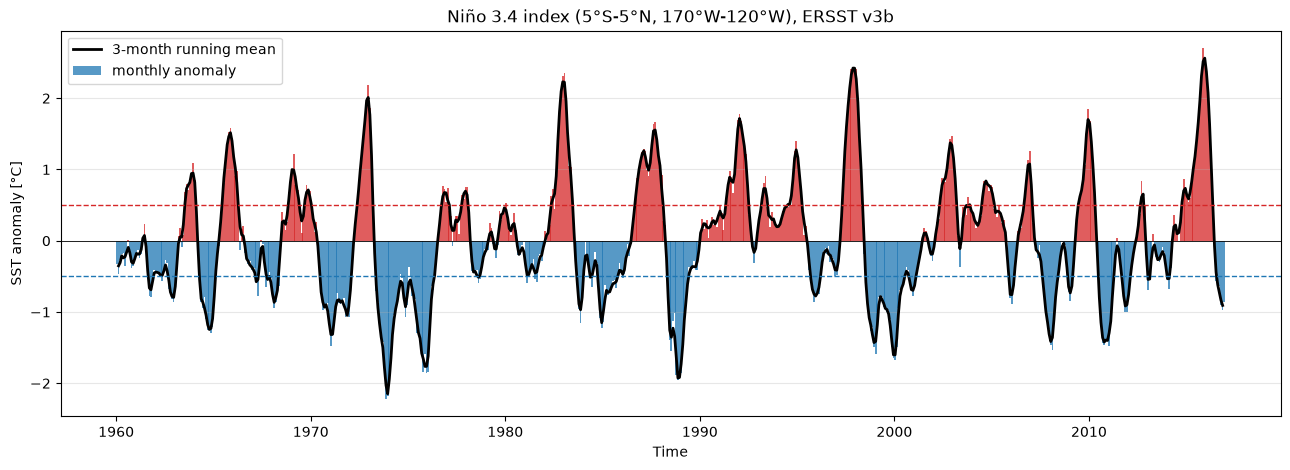

In [ ]:
# 2.2 绘制 Niño 3.4 指数（柱状 + 3 个月滑动 + ±0.5°C 阈值）

fig, ax = plt.subplots(figsize=(13, 4.8), dpi=110)

# 注意：直接给 bar() 传 datetime64 时柱宽会被算成 0（画不出来），
# 所以先转成 matplotlib 的日期数值，再调用 xaxis_date()
t_num = mdates.date2num(nino34.time.values)
colors = np.where(nino34.values > 0, "tab:red", "tab:blue")
ax.bar(t_num, nino34.values, width=32, color=colors, alpha=0.75,
       label="monthly anomaly")

t3_num = mdates.date2num(nino34_3m.time.values)
ax.plot(t3_num, nino34_3m.values, color="k", lw=2,
        label="3-month running mean")
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.YearLocator(10))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.axhline(0.5, color="tab:red", ls="--", lw=1)
ax.axhline(-0.5, color="tab:blue", ls="--", lw=1)
ax.axhline(0, color="k", lw=0.6)

ax.set_ylabel("SST anomaly [°C]")
ax.set_xlabel("Time")
ax.set_title("Niño 3.4 index (5°S-5°N, 170°W-120°W), ERSST v3b")
ax.grid(alpha=0.3, axis="y")
ax.legend(loc="upper left")

plt.tight_layout()

plt.show()

In [ ]:
# 顺便用 ONI 定义（3 个月滑动平均 ±0.5°C 持续 5 个月以上）找出 El Niño / La Niña 事件

def find_events(series, threshold=0.5, min_len=5):
    flag = (series >= threshold).values
    events, start = [], None
    for i, f in enumerate(flag):
        if f and start is None:
            start = i
        if not f and start is not None:
            if i - start >= min_len:
                events.append((series.time.values[start], series.time.values[i - 1]))
            start = None
    if start is not None and len(flag) - start >= min_len:
        events.append((series.time.values[start], series.time.values[-1]))
    return events


el_nino = find_events(nino34_3m, 0.5)
la_nina = find_events(-nino34_3m, 0.5)

print("El Nino events (ONI >= 0.5 for >= 5 months):")
for s, e in el_nino:
    print("   ", str(s)[:7], "->", str(e)[:7])
print("La Nina events (ONI <= -0.5 for >= 5 months):")
for s, e in la_nina:
    print("   ", str(s)[:7], "->", str(e)[:7])

El Nino events (ONI >= 0.5 for >= 5 months):
    1963-07 -> 1964-01
    1965-06 -> 1966-03
    1968-11 -> 1969-05
    1972-06 -> 1973-02
    1976-10 -> 1977-02
    1982-05 -> 1983-06
    1986-09 -> 1988-01
    1991-05 -> 1992-06
    1994-07 -> 1995-03
    1997-05 -> 1998-04
    2002-05 -> 2003-03
    2004-07 -> 2005-02
    2006-09 -> 2007-01
    2009-06 -> 2010-04
    2014-10 -> 2016-05
La Nina events (ONI <= -0.5 for >= 5 months):
    1962-09 -> 1963-01
    1964-04 -> 1965-01
    1967-10 -> 1968-04
    1970-07 -> 1972-01
    1973-05 -> 1976-04
    1984-10 -> 1985-09
    1988-05 -> 1989-05
    1995-09 -> 1996-03
    1998-07 -> 2000-06
    2007-08 -> 2008-05
    2010-07 -> 2011-03
    2011-09 -> 2012-02


**2 描述：** 1960–2016 年间 Niño 3.4 月异常在 −2.2 ~ +2.7 °C 之间，3 个月滑动平均在 −2.2 ~ +2.6 °C 之间。
按 ONI 定义（±0.5 °C 持续 5 个月以上）识别出 **15 次厄尔尼诺**和 **12 次拉尼娜**：
最强暖事件是 1982-05~1983-06、1997-05~1998-04、2014-10~2016-05；
最强冷事件是 1973-05~1976-04、1988-05~1989-05、1998-07~2000-06、2010-07~2011-03。
柱状图用红/蓝区分冷暖位相，黑线是 3 个月滑动平均，橙色虚线是 ±0.5 °C 判定阈值；
图形态与 NOAA 的 ONI 监测图一致。

## 3. Explore a netCDF dataset

数据集：**ERA5-Land monthly averaged**（欧盟 Copernicus Climate Data Store，ECMWF 制作），
变量 `t2m`（2 米气温），**2000-01 ~ 2023-12，共 288 个月**，
空间范围 **15°N–55°N、70°E–140°E**（覆盖中国全域，0.1° 网格，401 × 701）。
文件格式 NetCDF4，来自 CDS 官网下载（数据集 ID：`reanalysis-era5-land-monthly-means`）。

> 注：CDS 新版 NetCDF 的时间坐标名为 `valid_time`，下面统一重命名为 `time`；
> 单位由 K 换算为 °C；海洋格点为 NaN（ERA5-Land 只覆盖陆地），
> 区域平均与趋势计算都自动跳过缺测。


In [ ]:
# 3.0 读取 ERA5-Land 数据
# 中文标签需要指定字体，否则显示成方块
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
ds3 = load_nc(os.path.join(DATA_DIR, "era5_land_t2m_china_2000_2023.nc"))
print(ds3)

# 时间坐标改名，温度换算成 °C
t2m = ds3.t2m.rename({"valid_time": "time"}) - 273.15
t2m.attrs.update(long_name="2m temperature", units="degC")
lat3, lon3 = t2m.latitude.values, t2m.longitude.values
print("time:", str(t2m.time.values[0])[:10], "->", str(t2m.time.values[-1])[:10])
print("shape:", t2m.shape, "  缺测比例: %.1f%%" % (100 * float(t2m.isnull().mean())))

<xarray.Dataset> Size: 324MB
Dimensions:     (valid_time: 288, latitude: 401, longitude: 701)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 2kB 2000-01-01 ... 2023-12-01
    expver      (valid_time) <U4 5kB ...
  * latitude    (latitude) float64 3kB 55.0 54.9 54.8 54.7 ... 15.2 15.1 15.0
  * longitude   (longitude) float64 6kB 70.0 70.1 70.2 ... 139.8 139.9 140.0
    number      int64 8B ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 324MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-08T15:51 GRIB to CDM+CF via cfgrib-0.9.1...
time: 2000-01-01 -> 2023-12-01
shape: (288, 401, 701)   缺测比例: 24.4%


区域平均气温: -5.7 -> -2.8 °C
季节循环振幅: 25.6 °C
去季节后范围: -2.9 ~ 2.1 °C


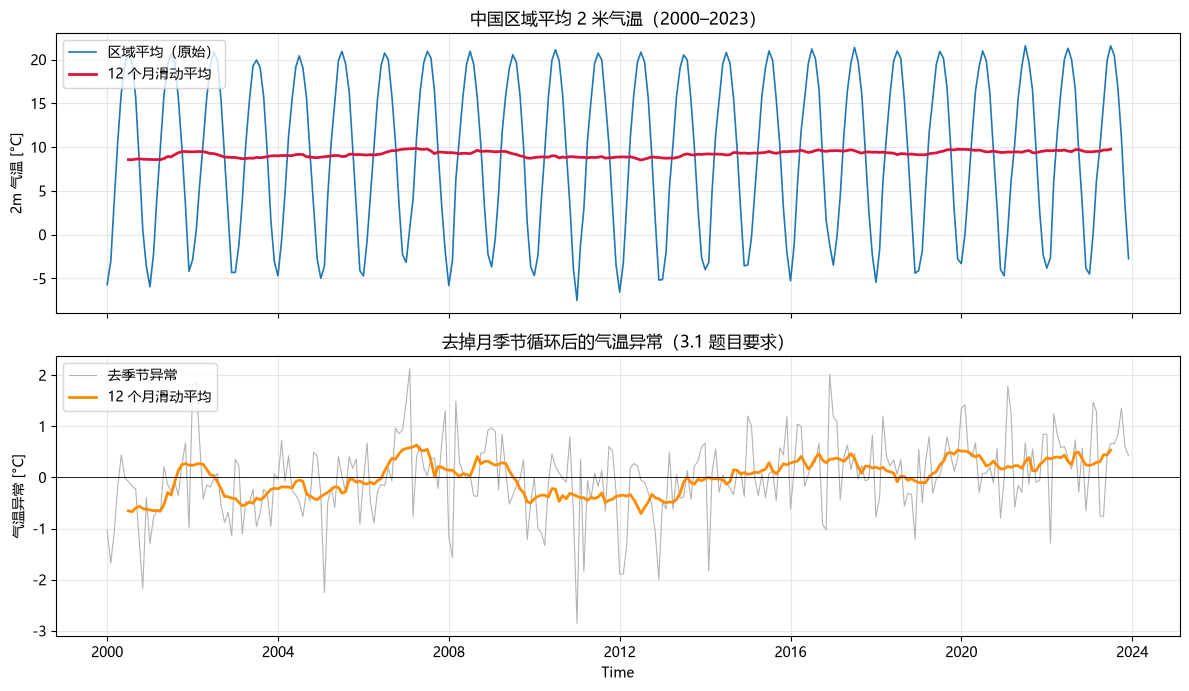

In [ ]:
# 3.1 区域平均气温的时间序列（去掉月季节循环）
w3 = np.cos(np.deg2rad(t2m.latitude))
ts = t2m.weighted(w3).mean(dim=["latitude", "longitude"])      # 面积加权的区域平均

g3 = ts.groupby("time.month")
clim3 = g3.mean("time")            # 12 个月的多年平均（气候态）
anom3 = g3 - clim3                 # 去季节异常
anom3_12 = anom3.rolling(time=12, center=True).mean()

print("区域平均气温: %.1f -> %.1f °C" % (float(ts.isel(time=0)), float(ts.isel(time=-1))))
print("季节循环振幅: %.1f °C" % (float(clim3.max() - clim3.min())))
print("去季节后范围: %.1f ~ %.1f °C" % (float(anom3.min()), float(anom3.max())))

fig, axes = plt.subplots(2, 1, figsize=(12, 7), dpi=110, sharex=True)

axes[0].plot(ts.time, ts.values, color="tab:blue", lw=1.2, label="区域平均（原始）")
axes[0].plot(ts.time, ts.rolling(time=12, center=True).mean().values,
             color="crimson", lw=2, label="12 个月滑动平均")
axes[0].set_ylabel("2m 气温 [°C]")
axes[0].set_title("中国区域平均 2 米气温（2000–2023）")
axes[0].legend(loc="upper left")
axes[0].grid(alpha=0.3)

axes[1].plot(anom3.time, anom3.values, color="0.7", lw=0.8, label="去季节异常")
axes[1].plot(anom3_12.time, anom3_12.values, color="darkorange", lw=2,
             label="12 个月滑动平均")
axes[1].axhline(0, color="k", lw=0.6)
axes[1].set_ylabel("气温异常 [°C]")
axes[1].set_xlabel("Time")
axes[1].set_title("去掉月季节循环后的气温异常（3.1 题目要求）")
axes[1].legend(loc="upper left")
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.show()

气候态范围: -31.8 ~ 36.5 °C


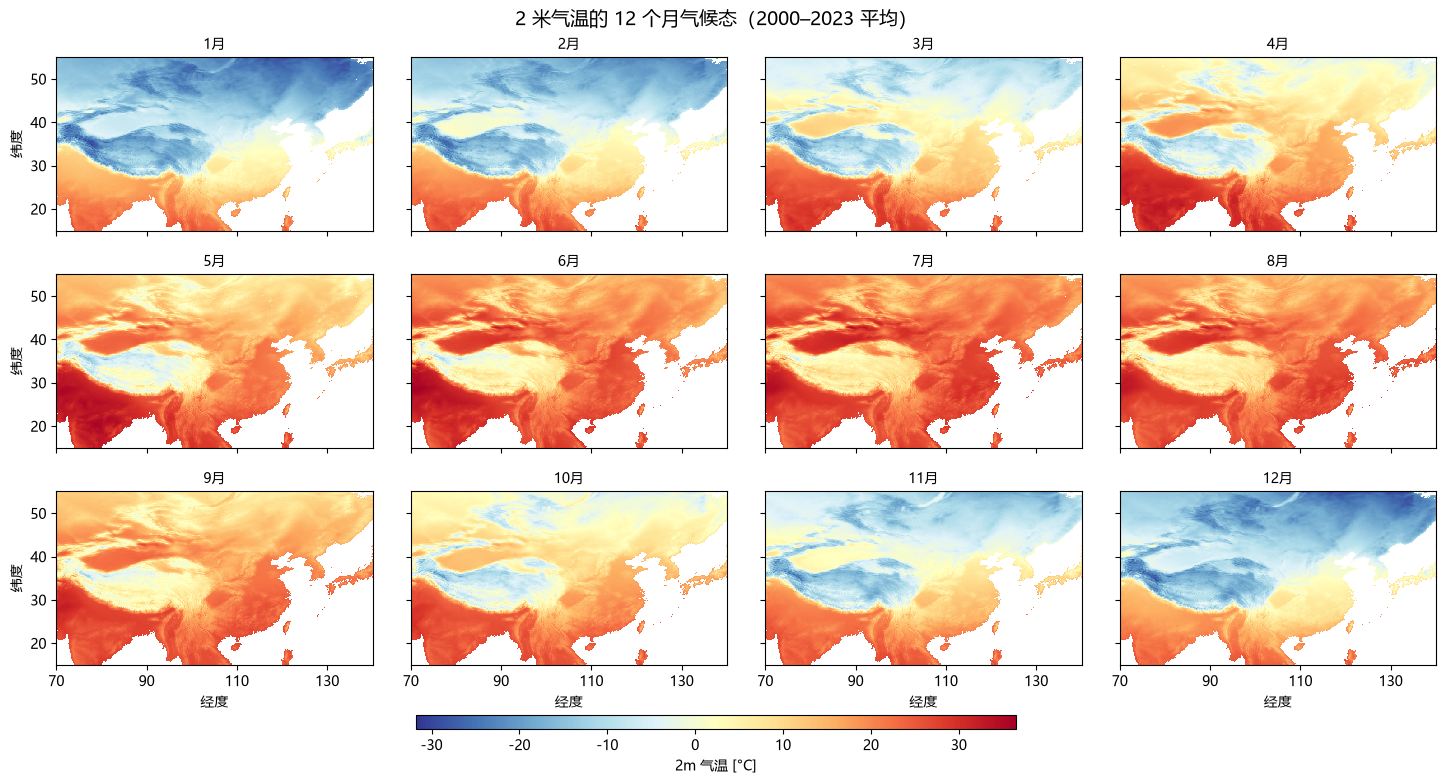

In [ ]:
# 3.2-(1) 12 个月的气候态（空间分布）
clim_map = t2m.groupby("time.month").mean("time")
vmin, vmax = float(clim_map.min()), float(clim_map.max())
print("气候态范围: %.1f ~ %.1f °C" % (vmin, vmax))

months = ["1月", "2月", "3月", "4月", "5月", "6月",
          "7月", "8月", "9月", "10月", "11月", "12月"]

fig, axes = plt.subplots(3, 4, figsize=(15, 8), dpi=110, sharex=True, sharey=True)
for i, ax in enumerate(axes.ravel()):
    m = clim_map.isel(month=i)
    pc = ax.pcolormesh(lon3, lat3, m, cmap="RdYlBu_r", vmin=vmin, vmax=vmax,
                       shading="auto")
    ax.set_title(months[i], fontsize=10)
    ax.set_xticks([70, 90, 110, 130])
    ax.set_yticks([20, 30, 40, 50])
for ax in axes[-1, :]:
    ax.set_xlabel("经度")
for ax in axes[:, 0]:
    ax.set_ylabel("纬度")
fig.subplots_adjust(left=0.06, right=0.98, top=0.90, bottom=0.14,
                    wspace=0.12, hspace=0.25)
cax = fig.add_axes([0.30, 0.06, 0.40, 0.018])
fig.colorbar(pc, cax=cax, orientation="horizontal", label="2m 气温 [°C]")
fig.suptitle("2 米气温的 12 个月气候态（2000–2023 平均）", fontsize=14, y=0.96)

plt.show()

趋势范围: -0.48 ~ 1.47 °C/decade
区域平均趋势: 0.28 °C/decade


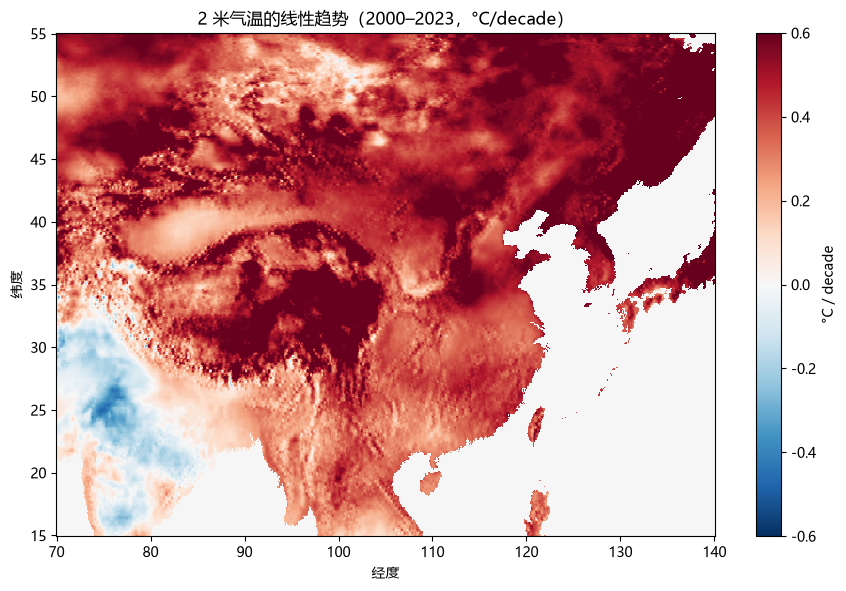

In [ ]:
# 3.2-(2) 2000–2023 线性趋势的空间分布（°C/decade）
tt = t2m.time.dt.year + (t2m.time.dt.month - 0.5) / 12
tt = tt - tt.mean()
trend = (t2m * tt).sum("time") / (tt ** 2).sum()      # 最小二乘斜率
trend = trend * 10                                     # 每十年

print("趋势范围: %.2f ~ %.2f °C/decade" % (float(trend.min()), float(trend.max())))
print("区域平均趋势: %.2f °C/decade" % float(trend.weighted(w3).mean()))

fig, ax = plt.subplots(figsize=(9, 6), dpi=110)
pc = ax.pcolormesh(lon3, lat3, trend, cmap="RdBu_r", vmin=-0.6, vmax=0.6,
                   shading="auto")
ax.set_xlabel("经度"); ax.set_ylabel("纬度")
ax.set_title("2 米气温的线性趋势（2000–2023，°C/decade）")
fig.colorbar(pc, ax=ax, label="°C / decade")

plt.tight_layout()

plt.show()

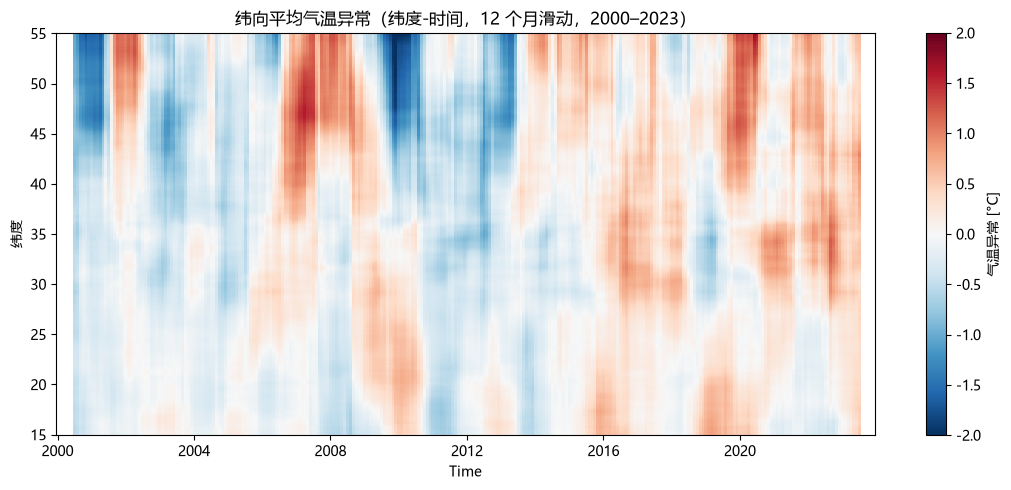

In [ ]:
# 3.2-(3) 纬度-时间 Hovmöller 图（纬向平均的去季节异常）
# 注意：anom3 是区域平均后的一维序列，这里要从三维场重新算异常
anom_map = t2m.groupby("time.month") - t2m.groupby("time.month").mean("time")
zm = anom_map.mean("longitude")                    # (time, latitude)
zm = zm.rolling(time=12, center=True).mean()       # 低频化，否则逐月太碎

fig, ax = plt.subplots(figsize=(11, 5), dpi=110)
pc = ax.pcolormesh(zm.time, zm.latitude, zm.T, cmap="RdBu_r",
                   vmin=-2, vmax=2, shading="auto")
ax.set_ylabel("纬度"); ax.set_xlabel("Time")
ax.set_title("纬向平均气温异常（纬度-时间，12 个月滑动，2000–2023）")
fig.colorbar(pc, ax=ax, label="气温异常 [°C]")

plt.tight_layout()

plt.show()

最暖年: 2007 (9.78 °C)
最冷年: 2012 (8.52 °C)


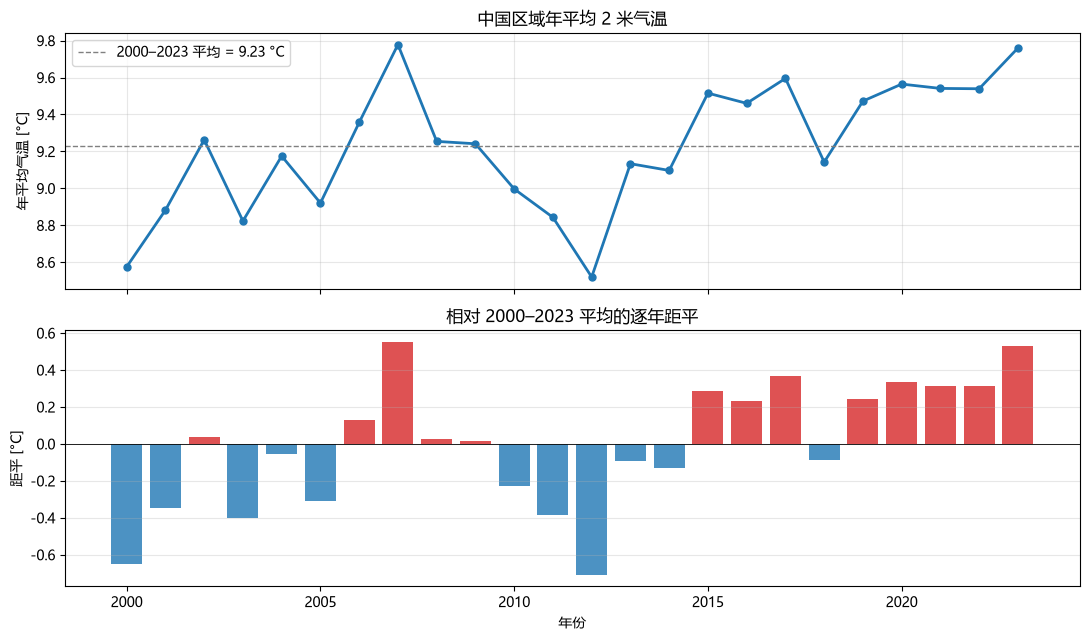

In [ ]:
# 3.2-(4) 年平均序列与逐年距平
annual = ts.groupby("time.year").mean("time")
annual_anom = annual - annual.mean()
year_x = annual.year.values.astype(int)

print("最暖年: %d (%.2f °C)" % (year_x[annual.argmax()], float(annual.max())))
print("最冷年: %d (%.2f °C)" % (year_x[annual.argmin()], float(annual.min())))

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), dpi=110, sharex=True)

axes[0].plot(year_x, annual.values, "o-", color="tab:blue", lw=2, ms=5)
axes[0].axhline(float(annual.mean()), color="gray", ls="--", lw=1,
                label="2000–2023 平均 = %.2f °C" % float(annual.mean()))
axes[0].set_ylabel("年平均气温 [°C]")
axes[0].set_title("中国区域年平均 2 米气温")
axes[0].legend()
axes[0].grid(alpha=0.3)

colors = np.where(annual_anom.values > 0, "tab:red", "tab:blue")
axes[1].bar(year_x, annual_anom.values, color=colors, alpha=0.8)
axes[1].axhline(0, color="k", lw=0.6)
axes[1].set_ylabel("距平 [°C]")
axes[1].set_xlabel("年份")
axes[1].set_title("相对 2000–2023 平均的逐年距平")
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()

plt.show()

最近格点: 27.3°N, 111.5°E
家乡季节循环: 5.6 ~ 28.4 °C，振幅 22.8 °C


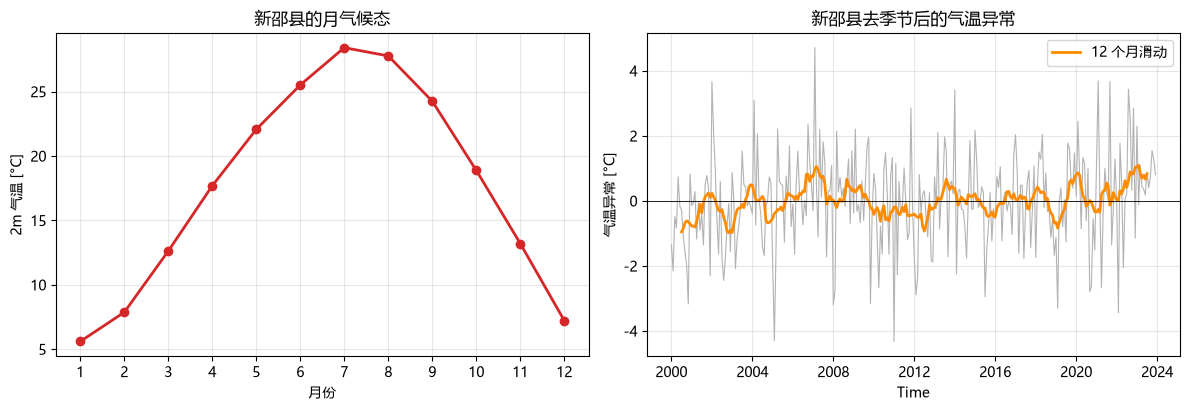

In [ ]:
# 3.2-(5) 家乡（湖南邵阳新邵县）的季节循环与气温异常
home_lon, home_lat = 111.4541, 27.3246
pt3 = t2m.sel(longitude=home_lon, latitude=home_lat, method="nearest")
print("最近格点: %.1f°N, %.1f°E" % (float(pt3.latitude), float(pt3.longitude)))

pt_clim = pt3.groupby("time.month").mean("time")
pt_anom = pt3.groupby("time.month") - pt_clim
print("家乡季节循环: %.1f ~ %.1f °C，振幅 %.1f °C"
      % (float(pt_clim.min()), float(pt_clim.max()),
         float(pt_clim.max() - pt_clim.min())))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), dpi=110)

axes[0].plot(pt_clim.month, pt_clim.values, "o-", lw=2, color="tab:red", ms=6)
axes[0].set_xticks(np.arange(1, 13))
axes[0].set_xlabel("月份"); axes[0].set_ylabel("2m 气温 [°C]")
axes[0].set_title("新邵县的月气候态")
axes[0].grid(alpha=0.3)

axes[1].plot(pt_anom.time, pt_anom.values, color="0.7", lw=0.8)
axes[1].plot(pt_anom.time, pt_anom.rolling(time=12, center=True).mean().values,
             color="darkorange", lw=2, label="12 个月滑动")
axes[1].axhline(0, color="k", lw=0.6)
axes[1].set_xlabel("Time"); axes[1].set_ylabel("气温异常 [°C]")
axes[1].set_title("新邵县去季节后的气温异常")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.show()

变暖幅度: -0.73 ~ 1.68 °C，区域平均 0.34 °C


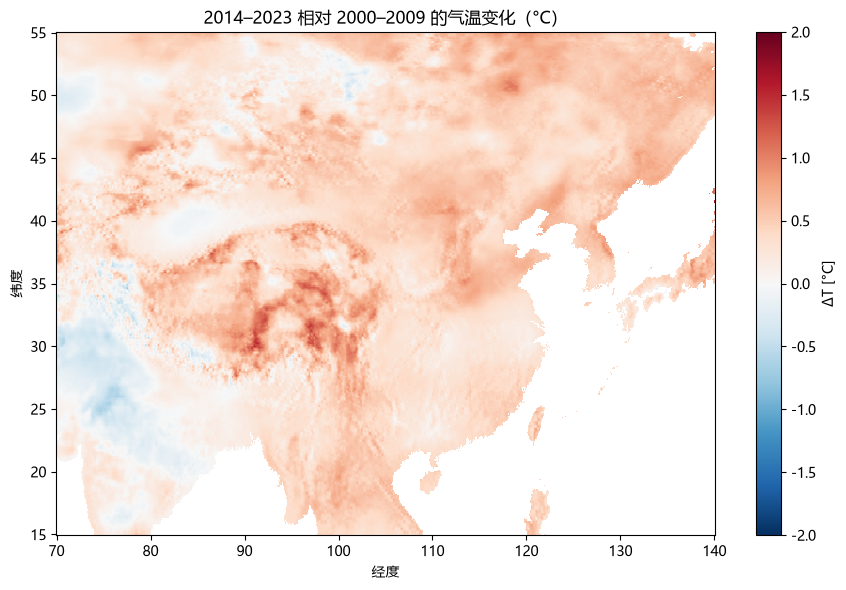

In [ ]:
# 3.2-(6) 近期（2014–2023）相对早期（2000–2009）的变暖分布
early = t2m.sel(time=slice("2000-01-01", "2009-12-31")).mean("time")
late = t2m.sel(time=slice("2014-01-01", "2023-12-31")).mean("time")
diff = late - early
print("变暖幅度: %.2f ~ %.2f °C，区域平均 %.2f °C"
      % (float(diff.min()), float(diff.max()), float(diff.weighted(w3).mean())))

fig, ax = plt.subplots(figsize=(9, 6), dpi=110)
pc = ax.pcolormesh(lon3, lat3, diff, cmap="RdBu_r", vmin=-2, vmax=2,
                   shading="auto")
ax.set_xlabel("经度"); ax.set_ylabel("纬度")
ax.set_title("2014–2023 相对 2000–2009 的气温变化（°C）")
fig.colorbar(pc, ax=ax, label="ΔT [°C]")

plt.tight_layout()

plt.show()

**3 描述：** 这份 ERA5-Land 月平均数据覆盖中国全域 2000–2023 年共 **288 个月**，
0.1° 网格（401 × 701，约 324 MB）。区域平均 2 米气温的**季节循环振幅约 25.6 °C**
（1 月最低、7 月最高），12 个月气候态的空间范围是 **−31.8 ~ 36.5 °C**。

**3.1**：去掉月季节循环后，区域平均气温异常在 **−2.9 ~ +2.1 °C** 之间波动；
12 个月滑动平均显示 2000–2012 年以负距平为主，2013 年以后转为持续正距平。

**3.2** 六张图：

1. **12 个月气候态**：冬季 −30 °C 等温线南压到 45°N 附近，夏季 20 °C 等温线北抬到 50°N，
   青藏高原全年偏冷（海拔效应清晰可见）。
2. **线性趋势**：范围 **−0.48 ~ +1.47 °C/decade**，区域平均 **0.28 °C/decade**；
   青藏高原、华北、东北增温最强，西南与云南部分地区出现负趋势。
3. **纬度-时间 Hovmöller**（12 个月滑动）：2007–2008 年与 2020 年前后中高纬（45–55°N）
   出现明显暖带，2010–2012 年该纬度带整体偏冷。
4. **年平均序列**：最暖年 **2007 年（9.78 °C）**，最冷年 **2012 年（8.52 °C）**，
   23 年均值 9.23 °C；2013 年以后除 2018 年外基本维持正距平。
5. **家乡新邵县**（最近格点 27.3°N, 111.5°E）：月气候态 **5.6 ~ 28.4 °C，振幅 22.8 °C**。
6. **近期变暖**（2014–2023 减 2000–2009）：变化 **−0.73 ~ +1.68 °C**，区域平均 **+0.34 °C**，
   高原与北方增温幅度大于南方。

需要说明的是：ERA5-Land 只覆盖陆地，区域内约 **24.4%** 的格点为缺测（海洋与境外部分），
因此所有区域统计都采用 cos(纬度) 加权并自动跳过缺测。
